# Cassini CDA Dust Analyzer: 3-OH vs non-3-OH Few-Shot Study

This notebook builds the few-shot "training" set for a binary **3-OH vs non-3-OH** classifier and tests it on labelled spectra. It follows the 3-P peaks-focused study (`Notebooks/XX_3p_ablation_study_peaks_focused.ipynb`): the same crop, Q_I window and Lee v2 scaling, contrastive Gemini explanations for each exemplar, one Vertex AI batch job and a confusion matrix.

### Differences from the 3-P study
- **Expert exemplars.** The 3-OH examples are the SCLKs in `3oh/sclks.txt`, chosen by the CDA expert (plots and a mass-domain description are in `3oh/`). Non-3-OH examples are sampled from the labelled train split.
- **Time-domain prompt.** The expert description in `3oh/prompt.txt` is written in m/z. Step 2 converts it into flight-time distances in µs. The plots sent to Gemini have a time-of-flight axis in µs, like the CDA analysis tool.
- **Frozen few-shot pool.** Exemplar images, their Gemini explanations and the prompts are saved to `study_results_3oh/few_shot_pool_3oh.json`. Notebook `16_3oh_inference.ipynb` loads this file, so the unlabelled data is classified with exactly what was tested here. The pool is rebuilt automatically when prompts, exemplars or the model change, or when `FORCE_REGENERATE_POOL = True`. You can edit the explanations in the JSON by hand; they are reused as long as nothing else changes.

### Outputs (`Notebooks/3oh_classification/study_results_3oh/`)
- `few_shot_pool_3oh.json`: exemplars, explanations and prompts (input for notebook 16)
- `requests_3oh_study.jsonl`: the batch request file
- `results_3oh_study.csv` / `.parquet`: one prediction per test spectrum
- `confusion_matrix_3oh.csv` / `.png`, `per_class_3oh.csv`, `misclassified_3oh.csv`, `metrics_3oh.json`

## Step 1: Imports and Configuration

In [14]:
import os
import sys
import json
import base64
import random
import asyncio
import hashlib
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from google import genai
from google.genai import types
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from dotenv import load_dotenv

import warnings
import logging
warnings.filterwarnings("ignore")
logging.getLogger("google_genai").setLevel(logging.WARNING)

# Repository root = the folder with pyproject.toml and the cda_dust_agent package, wherever the kernel was started.
# (Notebooks/cda_dust_agent/ is only a data folder, so the package's __init__.py is required.)
def is_repo_root(path):
    return (os.path.isfile(os.path.join(path, "pyproject.toml"))
            and os.path.isfile(os.path.join(path, "cda_dust_agent", "__init__.py")))

project_root = os.path.abspath(os.getcwd())
while not is_repo_root(project_root):
    parent = os.path.dirname(project_root)
    if parent == project_root:
        raise RuntimeError("Repository root (pyproject.toml + cda_dust_agent/) not found; start Jupyter inside the repository.")
    project_root = parent
study_dir = os.path.join(project_root, "Notebooks", "3oh_classification")
print(f"Repository root: {project_root}")

if not load_dotenv(dotenv_path=os.path.join(project_root, ".env")):
    print("Warning: no .env loaded; the defaults in cda_dust_agent/config.py are used for project and bucket.")
sys.path.extend([project_root, study_dir])

from cda_dust_agent.config import Config
import cda_3oh_common as c3

Repository root: /workspaces/cda-dust-analyzer


In [15]:
# Expert input: SCLK list, plots and mass-domain description of 3-OH
EXEMPLAR_DIR = os.path.join(project_root, "3oh")
if not os.path.isdir(EXEMPLAR_DIR):
    EXEMPLAR_DIR = os.path.join(study_dir, "3oh_sample_nozair")
EXEMPLAR_SCLK_FILE = os.path.join(EXEMPLAR_DIR, "sclks.txt")
EXPERT_DESCRIPTION_FILE = os.path.join(EXEMPLAR_DIR, "prompt.txt")
CATALOGUE_CSV = os.path.join(project_root, "Notebooks", "cda_class_list.csv")

# Outputs
OUTPUT_DIR = os.path.join(study_dir, "study_results_3oh")
FEW_SHOT_POOL_PATH = os.path.join(OUTPUT_DIR, "few_shot_pool_3oh.json")  # read by notebook 16
FORCE_REGENERATE_POOL = False  # True = ask Gemini for new exemplar explanations even if the saved pool still matches

# Non-3-OH few-shot exemplars, sampled per catalogue class from the labelled split
NEGATIVE_SHOTS = {"Noise": 2, "1": 2, "2": 2, "4": 2, "5": 2, "5-Na": 2}
RANDOM_SEED = 123

# Ground truth of each catalogue class in the test set (classes not listed, e.g. ?, X, 2-X, are dropped).
# The nine expert spectra are 3-OH whatever their catalogue label; they are few-shot examples, never test data.
# A class can also be set to "report_only": classified and listed per class, but left out of the scores.
LABEL_ROLE = {
    "3-OH": c3.LABEL_3OH,
    "Noise": c3.LABEL_NON_3OH,
    "1": c3.LABEL_NON_3OH,
    "2": c3.LABEL_NON_3OH,
    "4": c3.LABEL_NON_3OH,
    "5": c3.LABEL_NON_3OH,
    "5-Na": c3.LABEL_NON_3OH,
    "3-Cl": c3.LABEL_NON_3OH,
    "3-Car": c3.LABEL_NON_3OH,
    "3-KNa": c3.LABEL_NON_3OH,
    "3-K": c3.LABEL_NON_3OH,
    "3-P": c3.LABEL_NON_3OH,
}
TEST_CAP_PER_CLASS = 100

configs = Config()
MODEL_ID = configs.agent_settings.model
# None = the model's default temperature. A lower value (e.g. 0.0) makes reruns more repeatable,
# but Google recommends keeping Gemini 3 models at their default of 1.0.
TEMPERATURE = None

os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f"Model: {MODEL_ID} | project: {configs.agent_settings.project_id} | bucket: {configs.agent_settings.bucket_name}")
print(f"Outputs: {OUTPUT_DIR}")

Model: gemini-3.5-flash | project: turan-genai-bb | bucket: turansgenaibb
Outputs: /workspaces/cda-dust-analyzer/Notebooks/3oh_classification/study_results_3oh


## Step 2: Instrument Time Base and the Expert Description

The expert description (`3oh/prompt.txt`) uses m/z values and flight-time differences Δt. To apply it to our plots we need the time per lvl2 sample.

**Sampling rate (cross-check)**
- The TOF mass spectrum (multiplier signal) is sampled at **100 MHz, i.e. 10 ns per sample, for 6.4 µs after the trigger**. Sources: Postberg et al. 2008, §2; Postberg et al. 2018 and 2023, Methods; CDA Data Handbook §1.1.2 (texts in `scratch/papers_txt/` and `claude-cda/scratch/lit_claims/cdaDataHB.txt`). After 6.4 µs an extended, low-resolution spectrum is recorded at 10 MHz up to 40 µs (Postberg et al. 2018).
- **0.375 MHz** appears in the CDA Data Handbook as the *pre-trigger* sampling rate of the charge channels QC, QT and QI, which is raised to 6 MHz and 3 MHz after the trigger. It does not apply to the mass spectrum: one sample at 0.375 MHz lasts 2.67 µs, longer than the whole Na⁺ → Na(NaOH)⁺ distance of about 1.5 µs.
- Data check on the expert exemplars (repeated in Step 4): the Na⁺ maximum sits at lvl2 samples 147–197. At 10 ns per sample that is 1.47–1.97 µs, the same times the CDA analysis tool shows in `3oh/*.png` (e.g. 1498480760: sample 182 = 1.82 µs; tool: 1.83 µs). The Na(NaOH)⁺ peak follows 147–152 samples (1.47–1.52 µs) later.
- So the crop `spectrum[10:641]` used since the 3-P study covers 0.10–6.40 µs: the 100 MHz high-rate window, which holds masses up to about 185–200 u. The remaining 378 samples (the extended spectrum) are not used.

**Mass → time**

For singly charged ions t = t₀ + a·√(m/z), with a = 0.473 µs (Postberg et al. 2023, Methods). t₀ varies between spectra; in the exemplars by about 0.5 µs. The prompt therefore uses time *differences*, which do not depend on t₀: Δt = a·(√m₂ − √m₁).

| from → to | computed Δt | expert (`prompt.txt`) |
|---|---|---|
| m/z 23 → 63 | 1.49 µs | about 1.5–1.6 µs |
| m/z 63 → 81 | 0.50 µs | about 0.5 µs |
| m/z 63 → 103 | 1.05 µs | about 1.0–1.2 µs |

The table in the next cell is computed from `MASS_LINES`. Edit that list (e.g. uncomment m/z 143) to change the prompt in Step 5.

In [16]:
with open(EXPERT_DESCRIPTION_FILE) as f:
    EXPERT_DESCRIPTION_MASS_DOMAIN = f.read().strip()
print("Expert description (mass domain):\n")
print(EXPERT_DESCRIPTION_MASS_DOMAIN)

# Mass lines of the 3-OH pattern: (m/z, ion, role). Role: "anchor" = highest peak, "required" or "optional".
MASS_LINES = [
    (23.0, "Na+", "anchor"),
    (63.0, "Na(NaOH)+, the first sodium hydroxide cluster", "required"),
    (81.0, "Na(NaOH)(H2O)+, a hydrated hydroxide cluster; can also be Na(NaCl)+", "optional"),
    (103.0, "Na(NaOH)2+, the second hydroxide cluster; can also be Rh+ from the rhodium target", "optional"),
    # (143.0, "Na(NaOH)3+, the third hydroxide cluster", "optional"),  # labelled in several exemplar plots, not in prompt.txt
]
line_table = c3.mass_line_table(MASS_LINES)
display(line_table)

Expert description (mass domain):

These are generic type 3 spectra where we have Na peak at m/
23 as the highest amplitude and the next generic feature is at Del(T)
about 1.5 or 1.6 microseconds at m/z 63. In addition, some instances,
there is another peak at m/z 81 where the Del(T) between 63 and 81 is
about 0.5 microseconds. This 81 peak is corresponding to either
Na(NaOH)(H20) or Na(NaCl).

In addition, there could be another feature/peak at m/z around 102 (103),
where the Del (T) between 63 and 103 is about 1 to 1.2 microseconds. This
feature could be Na(NaOH)(NaOH) or may be Rhodium (Rh) feature.


,m/z (u),ion,role,dt after m/z 23 (us),dt after m/z 23 (samples),dt after m/z 63 (us)
0,23.0,Na+,anchor,0.000,0,-1.486
1,63.0,"Na(NaOH)+, the first sodium hydroxide cluster",required,1.486,149,0.000
2,81.0,"Na(NaOH)(H2O)+, a hydrated hydroxide cluster; ...",optional,1.989,199,0.503
3,103.0,"Na(NaOH)2+, the second hydroxide cluster; can ...",optional,2.532,253,1.046


## Step 3: Load Labelled Spectra and the Expert Exemplars

- **Labelled spectra:** the HF train split, filtered to length 1018 and the Q_I window, cropped and Lee v2 scaled exactly as in the 3-P study.
- **Expert exemplars:** read from both lvl2 files, because most were never labelled. At the time of writing, 7 are in the unlabelled split and 2 in the labelled split (catalogued 3-Car and 3-Cl). `sclks.txt` lists 1498480760 twice; duplicates are ignored.

In [17]:
catalogue = c3.load_catalogue(CATALOGUE_CSV)
train_path = c3.hf_path(c3.HF_TRAIN_FILE)
inf_path = c3.hf_path(c3.HF_INF_FILE)

# Labelled spectra: only catalogue classes that have a role in this study (drops ?, X, 2-X)
train_raw = pd.read_parquet(train_path)
print(f"Loaded {len(train_raw)} labelled spectra.")
train_df = c3.in_qi_window(train_raw[train_raw["class"].isin(list(LABEL_ROLE))])
train_df = c3.preprocess(train_df)
train_df["role"] = train_df["class"].map(LABEL_ROLE)
print(f"{len(train_df)} labelled spectra in the Q_I window after preprocessing:")
print(train_df["class"].value_counts().to_string())

# Expert 3-OH exemplars
with open(EXEMPLAR_SCLK_FILE) as f:
    listed_sclks = [int(line.strip()) for line in f if line.strip()]
exemplar_sclks = list(dict.fromkeys(listed_sclks))
if len(exemplar_sclks) != len(listed_sclks):
    print(f"\nNote: {len(listed_sclks) - len(exemplar_sclks)} duplicate SCLK(s) in {EXEMPLAR_SCLK_FILE} ignored.")

exemplars_raw = pd.concat(
    [c3.read_spectra(train_path, exemplar_sclks), c3.read_spectra(inf_path, exemplar_sclks)],
    ignore_index=True,
).drop_duplicates("sclk")
missing = sorted(set(exemplar_sclks) - set(exemplars_raw["sclk"]))
if missing:
    raise ValueError(f"Exemplar SCLKs not found in the lvl2 files: {missing}")

positive_df = c3.preprocess(exemplars_raw).set_index("sclk").loc[exemplar_sclks].reset_index()
positive_df = positive_df.merge(catalogue[["sclk", "catalogue_class"]], on="sclk", how="left")
positive_df["qi_in_window"] = positive_df["qi_ampl"].between(c3.QI_MIN_C, c3.QI_MAX_C)
print(f"\n{len(positive_df)} expert 3-OH exemplars:")
print(positive_df[["sclk", "event_id", "qi_ampl", "qi_in_window", "catalogue_class"]].to_string(index=False))

2026-10-19 14:08:19,695 - [httpx] - INFO - HTTP Request: HEAD https://huggingface.co/datasets/CosmicDustGroup/cassini-cda-spectra/resolve/main/data/lvl2/cda_qm_spectra_pre2008277_train_lvl2.parquet "HTTP/1.1 302 Found"
2026-10-19 14:08:19,825 - [httpx] - INFO - HTTP Request: HEAD https://huggingface.co/datasets/CosmicDustGroup/cassini-cda-spectra/resolve/main/data/lvl2/cda_qm_spectra_pre2008277_inf_lvl2.parquet "HTTP/1.1 302 Found"


Loaded 18883 labelled spectra.
7028 labelled spectra in the Q_I window after preprocessing:
class
Noise    4471
1        1183
2         830
4         222
3-Car      88
3-OH       47
3-Cl       45
5          42
3-KNa      36
5-Na       34
3-K        21
3-P         9

Note: 1 duplicate SCLK(s) in /workspaces/cda-dust-analyzer/3oh/sclks.txt ignored.

9 expert 3-OH exemplars:
      sclk  event_id      qi_ampl  qi_in_window catalogue_class
1498480760     56258 2.163970e-14          True               3
1498498974      3687 3.513730e-14          True            3-Cl
1498498908      3665 3.103810e-14          True             NaN
1498497629      3283 1.577320e-14          True             NaN
1498494880      2233 2.866220e-14          True           3-Car
1498492459      1058 3.051370e-14          True             NaN
1498491661       610 1.267020e-14          True             NaN
1498490432     65362 1.122330e-14          True             NaN
1498489361     64576 3.711970e-14          True  

## Step 4: Check the Time Base on the Exemplars

For each exemplar the highest peak is taken as Na⁺, t₀ is derived from it, and the expected times of the other mass lines are drawn as dashed lines. If the time base is right, the dashed lines sit on the expert-labelled peaks in `3oh/*.png`. The observed Na⁺ times set the window quoted in the prompt.

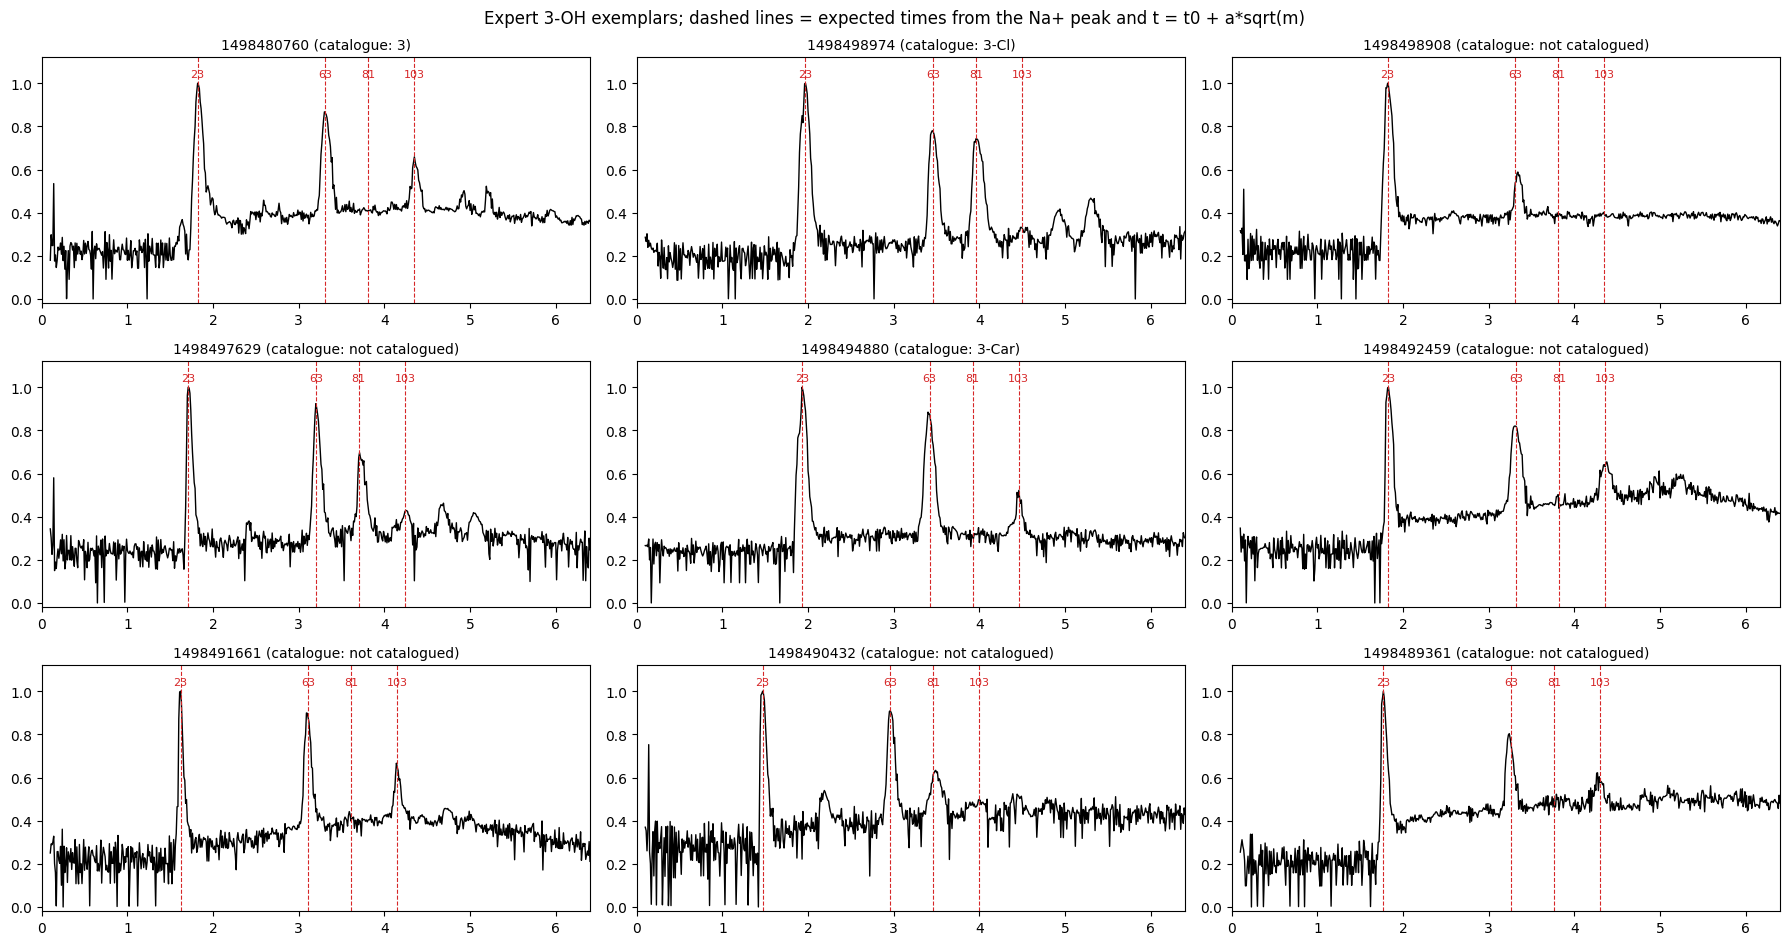

,sclk,t0_us,t_23u_us,height_23u,t_63u_us,height_63u,t_81u_us,height_81u,t_103u_us,height_103u,dt_23_63_us
0,1498480760,-0.45,1.82,1.0,3.30,0.87,3.89,0.43,4.35,0.66,1.48
1,1498498974,-0.30,1.97,1.0,3.45,0.78,3.96,0.74,4.48,0.33,1.48
2,1498498908,-0.45,1.82,1.0,3.34,0.59,3.80,0.40,4.34,0.40,1.52
3,1498497629,-0.56,1.71,1.0,3.20,0.92,3.71,0.70,4.25,0.43,1.49
4,1498494880,-0.34,1.93,1.0,3.40,0.88,3.99,0.35,4.46,0.52,1.47
5,1498492459,-0.44,1.83,1.0,3.30,0.82,3.89,0.51,4.37,0.65,1.47
6,1498491661,-0.65,1.62,1.0,3.09,0.90,3.59,0.44,4.14,0.67,1.47
7,1498490432,-0.80,1.47,1.0,2.96,0.91,3.49,0.63,3.99,0.50,1.49
8,1498489361,-0.50,1.77,1.0,3.24,0.80,3.79,0.52,4.27,0.62,1.47


Na+ peak at 1.47-1.97 us -> window quoted in the prompt: 1.4-2.0 us
Observed dt(23 -> 63 u): 1.47-1.52 us (computed 1.49 us; expert: about 1.5-1.6 us)


In [18]:
check_masses = [m for m, _, _ in MASS_LINES]
check_rows = []
n_rows = int(np.ceil(len(positive_df) / 3))
fig, axes = plt.subplots(n_rows, 3, figsize=(18, 3.2 * n_rows), squeeze=False)
for ax, row in zip(axes.flat, positive_df.itertuples(index=False)):
    t0, lines = c3.locate_mass_lines(row.spectrum, check_masses)
    observed = {line["m/z"]: line for line in lines}
    entry = {"sclk": row.sclk, "t0_us": round(t0, 2)}
    for line in lines:
        entry[f"t_{line['m/z']:g}u_us"] = line["t_observed_us"]
        entry[f"height_{line['m/z']:g}u"] = line["height"]
    entry["dt_23_63_us"] = round(observed[63.0]["t_observed_us"] - observed[23.0]["t_observed_us"], 2)
    check_rows.append(entry)

    t = c3.sample_time_us(np.arange(c3.CROP_START, c3.CROP_START + len(row.spectrum)))
    ax.plot(t, row.spectrum, color="black", linewidth=1)
    for line in lines:
        ax.axvline(line["t_expected_us"], color="tab:red", linestyle="--", linewidth=0.8)
        ax.text(line["t_expected_us"], 1.02, f"{line['m/z']:g}", color="tab:red", fontsize=8, ha="center", va="bottom")
    catalogue_label = row.catalogue_class if isinstance(row.catalogue_class, str) else "not catalogued"
    ax.set_title(f"{row.sclk} (catalogue: {catalogue_label})", fontsize=10)
    ax.set_xlim(0, 6.4)
    ax.set_ylim(-0.02, 1.12)
for ax in list(axes.flat)[len(positive_df):]:
    ax.axis("off")
plt.suptitle("Expert 3-OH exemplars; dashed lines = expected times from the Na+ peak and t = t0 + a*sqrt(m)")
plt.tight_layout()
plt.show()

check_df = pd.DataFrame(check_rows)
display(check_df)

na_times = check_df["t_23u_us"]
NA_WINDOW_US = (np.floor(na_times.min() * 10) / 10, np.ceil(na_times.max() * 10) / 10)
print(f"Na+ peak at {na_times.min():.2f}-{na_times.max():.2f} us -> window quoted in the prompt: "
      f"{NA_WINDOW_US[0]:.1f}-{NA_WINDOW_US[1]:.1f} us")
print(f"Observed dt(23 -> 63 u): {check_df['dt_23_63_us'].min():.2f}-{check_df['dt_23_63_us'].max():.2f} us "
      f"(computed {c3.delta_t_us(23, 63):.2f} us; expert: about 1.5-1.6 us)")

## Step 5: Prompts in the Time Domain

The expert rules are rewritten as time distances from the Na⁺ peak, computed from `MASS_LINES`. Following the expert, 3-OH is described by its hydroxide (OH) content, i.e. Na⁺ followed by the sodium hydroxide cluster ions Na(NaOH)ₙ⁺, not as a generic Type 3 spectrum. The *non-3-OH* description is a draft (not from `prompt.txt`); please review it, in particular the line on other salts.

In [19]:
dt_na = {m: float(c3.delta_t_us(23.0, m)) for m, _, _ in MASS_LINES}
dt_63 = {m: float(c3.delta_t_us(63.0, m)) for m, _, _ in MASS_LINES}
optional_lines = [(m, ion) for m, ion, role in MASS_LINES if role == "optional"]

optional_rules = "\n".join(
    f"{i}. Optional: a peak at m/z {m:g} ({ion}), about {dt_63[m]:.2f} µs after the m/z 63 peak ({dt_na[m]:.2f} µs after Na+)."
    for i, (m, ion) in enumerate(optional_lines, start=3)
)
optional_profile = "".join(f"; optionally m/z {m:g} about {dt_63[m]:.2f} µs after the m/z 63 peak" for m, _ in optional_lines)

SYSTEM_INSTRUCTION_TEXT = f"""You are an expert cosmic dust spectroscopist analysing time-of-flight (TOF) mass spectra recorded by the Cassini Cosmic Dust Analyzer (CDA).
Your task is to label each spectrum as '{c3.LABEL_3OH}' or '{c3.LABEL_NON_3OH}'.

How to read the plots:
- The x-axis is the ion time of flight in microseconds (0 to 6.4 µs; the detector is sampled at 100 MHz, i.e. 10 ns per sample). The y-axis is the log-scaled amplitude, normalised to 0-1.
- The flight time grows with the square root of the ion mass: t = t0 + {c3.STRETCH_A_US} µs x sqrt(m/z). The offset t0 differs from spectrum to spectrum, so a given ion can appear several tenths of a µs earlier or later. Identify peaks by their time distance from the Na+ peak, not by their absolute position. Allow about ±0.1 µs for every time distance.
- Ignore the vertical level of the baseline and any baseline shift.

Class '{c3.LABEL_3OH}' (salt-rich Type 3 ice grain containing sodium hydroxide, i.e. the OH group): after the Na+ peak the spectrum shows sodium hydroxide cluster ions Na(NaOH)n+, possibly with attached water.
1. The highest peak of the spectrum is Na+ (m/z 23). In the reference examples it lies between about {NA_WINDOW_US[0]:.1f} and {NA_WINDOW_US[1]:.1f} µs.
2. The first sodium hydroxide cluster Na(NaOH)+ (m/z 63) follows about {dt_na[63.0]:.2f} µs after the Na+ peak.
{optional_rules}
Rules 1 and 2 must both hold. The optional peaks continue the hydroxide series and support the label, but are not required.

Class '{c3.LABEL_NON_3OH}': every spectrum that does not show this sodium hydroxide pattern, for example
- the highest peak is not Na+, e.g. water-ice spectra dominated by a regularly spaced series of H3O+(H2O)n cluster peaks;
- a dominant Na+ peak without the Na(NaOH)+ peak about {dt_na[63.0]:.2f} µs later, e.g. extremely salt-rich spectra showing only Na+ (and K+);
- salt-rich spectra whose peaks after Na+ come mainly from other salts (chloride, carbonate, potassium or phosphate) rather than from the sodium hydroxide series;
- mineral spectra, or instrumental noise without a coherent peak pattern."""

PROFILES = {
    c3.LABEL_3OH: f"Sodium hydroxide (OH) pattern: highest peak Na+ (m/z 23); Na(NaOH)+ (m/z 63) about {dt_na[63.0]:.2f} µs later{optional_profile}.",
    c3.LABEL_NON_3OH: f"No sodium hydroxide pattern: the highest peak is not Na+, no Na(NaOH)+ peak follows about {dt_na[63.0]:.2f} µs after it, or the peaks after Na+ come mainly from other salts.",
}

CLASSIFICATION_USER_PROMPT = """Review the provided time-of-flight mass spectrum and label it '3-OH' or 'non-3-OH'.
First find the highest peak and decide whether it is Na+. Then measure the time distances (µs) from it to the next major peaks and compare them with the rules.

Format your output strictly as a JSON object with keys:
{
    "id": "<the provided sclk id>",
    "class": "<3-OH or non-3-OH>",
    "explanation": "<1-2 sentences naming the peak times in µs that decided the label>",
    "k": <the number of reference examples shown>
}
"""

CONTRASTIVE_ANNOTATION_USER_PROMPT = """You are an expert cosmic dust spectroscopist.
Write a brief, 1-2 sentence description of the key visual features of the Target Spectrum (Image A), labelled '{label}' ({detail}). It will be used as a reference example for '{label}'.

To help you write a contrastive description, reference spectra are attached:
- Image A (Target): the spectrum you must describe.
{reference_descriptions}

Use the time-domain rules from the system instruction. Name the approximate times (µs) of the decisive peaks and the time distances between them that make Image A '{label}' rather than '{other_label}'. Do not output JSON, just return the text description."""

print(SYSTEM_INSTRUCTION_TEXT)
print("\nProfiles:")
for label, profile in PROFILES.items():
    print(f"- {label}: {profile}")

You are an expert cosmic dust spectroscopist analysing time-of-flight (TOF) mass spectra recorded by the Cassini Cosmic Dust Analyzer (CDA).
Your task is to label each spectrum as '3-OH' or 'non-3-OH'.

How to read the plots:
- The x-axis is the ion time of flight in microseconds (0 to 6.4 µs; the detector is sampled at 100 MHz, i.e. 10 ns per sample). The y-axis is the log-scaled amplitude, normalised to 0-1.
- The flight time grows with the square root of the ion mass: t = t0 + 0.473 µs x sqrt(m/z). The offset t0 differs from spectrum to spectrum, so a given ion can appear several tenths of a µs earlier or later. Identify peaks by their time distance from the Na+ peak, not by their absolute position. Allow about ±0.1 µs for every time distance.
- Ignore the vertical level of the baseline and any baseline shift.

Class '3-OH' (salt-rich Type 3 ice grain containing sodium hydroxide, i.e. the OH group): after the Na+ peak the spectrum shows sodium hydroxide cluster ions Na(NaOH)n+, poss

## Step 6: Choose Negative Exemplars and the Test Set

- **Negative exemplars:** non-3-OH examples are drawn from the labelled split, `NEGATIVE_SHOTS` per catalogue class.
- **Test set:** up to `TEST_CAP_PER_CLASS` spectra per catalogue class, excluding every exemplar. The positives are the catalogued `3-OH` spectra.

**Ground truth (`LABEL_ROLE`)**
- **3-OH:** the nine expert spectra are 3-OH for the few-shot examples, whatever the catalogue says. Three of them are catalogued as `3` (1498480760), `3-Car` (1498494880) and `3-Cl` (1498498974). Being examples, they are never in the test set. In the test set, the catalogued `3-OH` spectra are the true 3-OH spectra used for recall.
- **non-3-OH:** every other class, including the other Type 3 sub-classes 3-Cl, 3-Car, 3-KNa, 3-K and 3-P.

The few-shot non-3-OH examples (`NEGATIVE_SHOTS`) do not include Type 3 sub-classes by default. Add e.g. `"3-Cl": 2` to show Gemini such hard negatives.

In [20]:
bad_negatives = [cls for cls in NEGATIVE_SHOTS if LABEL_ROLE.get(cls) != c3.LABEL_NON_3OH]
if bad_negatives:
    raise ValueError(f"NEGATIVE_SHOTS classes {bad_negatives} must have role '{c3.LABEL_NON_3OH}' in LABEL_ROLE.")

exemplar_set = set(exemplar_sclks)
candidates_df = train_df[~train_df["sclk"].isin(exemplar_set)]

negative_parts = []
for cls, n_shots in NEGATIVE_SHOTS.items():
    cls_df = candidates_df[candidates_df["class"] == cls]
    if len(cls_df) < n_shots:
        print(f"Warning: only {len(cls_df)} spectra of class {cls} for {n_shots} shots.")
    negative_parts.append(cls_df.sample(n=min(n_shots, len(cls_df)), random_state=RANDOM_SEED))
negative_df = pd.concat(negative_parts, ignore_index=True)

used_sclks = exemplar_set | set(negative_df["sclk"])
test_pool = train_df[~train_df["sclk"].isin(used_sclks)]
test_parts = []
for cls in LABEL_ROLE:
    cls_df = test_pool[test_pool["class"] == cls]
    if len(cls_df) > 0:
        test_parts.append(cls_df.sample(n=min(TEST_CAP_PER_CLASS, len(cls_df)), random_state=42))
test_df = pd.concat(test_parts, ignore_index=True)

print(f"Exemplars: {len(positive_df)} x {c3.LABEL_3OH} (expert) + {len(negative_df)} x {c3.LABEL_NON_3OH} "
      f"({negative_df['class'].value_counts().to_dict()})")
print(f"Test set: {len(test_df)} spectra")
print(test_df.groupby(["role", "class"]).size().rename("n").to_string())

Exemplars: 9 x 3-OH (expert) + 12 x non-3-OH ({'Noise': 2, '1': 2, '2': 2, '4': 2, '5': 2, '5-Na': 2})
Test set: 716 spectra
role      class
3-OH      3-OH      47
non-3-OH  1        100
          2        100
          3-Car     87
          3-Cl      44
          3-K       21
          3-KNa     36
          3-P        9
          4        100
          5         40
          5-Na      32
          Noise    100


## Step 7: Generate Contrastive Explanations for the Exemplars

This step works as in the 3-P study. Each exemplar is shown to Gemini together with one random reference image from every other group: the 3-OH exemplars and each negative catalogue class. Gemini writes a 1–2 sentence description, which goes into the few-shot prompt as "Specific Sample Features".

The result is saved as the few-shot pool. It is reused on the next run as long as the system instruction, the annotation prompt, the exemplars, the model and the time base are unchanged.

In [21]:
exemplar_df = pd.concat([
    positive_df.assign(label=c3.LABEL_3OH, group=c3.LABEL_3OH, detail="selected by the CDA expert as 3-OH"),
    negative_df.assign(label=c3.LABEL_NON_3OH, group=negative_df["class"],
                       detail=negative_df["class"].map(lambda c: f"catalogue class '{c}'")),
], ignore_index=True)[["sclk", "label", "group", "detail", "spectrum"]]
exemplar_df["image"] = [c3.render_spectrum_png(r.spectrum, f"{r.label} reference sample {r.sclk}")
                        for r in exemplar_df.itertuples(index=False)]

fingerprint = hashlib.sha256(json.dumps({
    "model": MODEL_ID,
    "temperature": TEMPERATURE,
    "system_instruction": SYSTEM_INSTRUCTION_TEXT,
    "annotation_prompt": CONTRASTIVE_ANNOTATION_USER_PROMPT,
    "exemplars": sorted(f"{s}:{l}" for s, l in zip(exemplar_df["sclk"], exemplar_df["label"])),
    "time_base": c3.time_base_settings(),
}, sort_keys=True).encode()).hexdigest()


async def generate_explanation(client, target, references, semaphore):
    ref_lines = "\n".join(f"- Image {chr(66 + i)}: Reference spectrum labelled '{ref.label}' ({ref.detail})"
                          for i, ref in enumerate(references))
    other_label = c3.LABEL_NON_3OH if target.label == c3.LABEL_3OH else c3.LABEL_3OH
    prompt = CONTRASTIVE_ANNOTATION_USER_PROMPT.format(label=target.label, detail=target.detail,
                                                       other_label=other_label, reference_descriptions=ref_lines)
    parts = [types.Part.from_text(text=prompt), types.Part.from_bytes(data=target.image, mime_type="image/png")]
    parts += [types.Part.from_bytes(data=ref.image, mime_type="image/png") for ref in references]
    async with semaphore:
        for attempt in range(3):
            try:
                response = await client.aio.models.generate_content(
                    model=MODEL_ID,
                    contents=[types.Content(role="user", parts=parts)],
                    config=types.GenerateContentConfig(system_instruction=SYSTEM_INSTRUCTION_TEXT, temperature=TEMPERATURE),
                )
                return target.sclk, response.text.strip()
            except Exception as e:
                print(f"Explanation for {target.sclk} failed: {e}. Retrying {attempt + 1}/3...")
                await asyncio.sleep(2 ** attempt)
    return target.sclk, None


async def generate_explanations(client, exemplar_df):
    random.seed(RANDOM_SEED)
    groups = {g: list(df.itertuples(index=False)) for g, df in exemplar_df.groupby("group", sort=False)}
    semaphore = asyncio.Semaphore(10)
    tasks = []
    for target in exemplar_df.itertuples(index=False):
        references = [random.choice(members) for g, members in groups.items() if g != target.group]
        tasks.append(generate_explanation(client, target, references, semaphore))
    results = dict(await asyncio.gather(*tasks))
    failed = [sclk for sclk, text in results.items() if not text]
    if failed:
        raise RuntimeError(f"No explanation for exemplars {failed}; rerun this cell.")
    return results


cached_pool = None
if os.path.exists(FEW_SHOT_POOL_PATH) and not FORCE_REGENERATE_POOL:
    with open(FEW_SHOT_POOL_PATH) as f:
        cached_pool = json.load(f)
    if cached_pool.get("fingerprint") != fingerprint:
        print("Saved pool was built with other prompts, exemplars, model or time base -> generating new explanations.")
        cached_pool = None

if cached_pool:
    explanations = {ex["sclk"]: ex["explanation"] for ex in cached_pool["exemplars"]}
    print(f"Reusing {len(explanations)} explanations from {FEW_SHOT_POOL_PATH}")
else:
    client = genai.Client()
    print(f"Generating explanations for {len(exemplar_df)} exemplars with {MODEL_ID}...")
    explanations = await generate_explanations(client, exemplar_df)

# Shuffle so that 3-OH and non-3-OH examples are interleaved in the prompt
ordered = exemplar_df.sample(frac=1, random_state=RANDOM_SEED)
pool = {
    "fingerprint": fingerprint,
    "created": datetime.now().isoformat(timespec="seconds"),
    "model": MODEL_ID,
    "temperature": TEMPERATURE,
    "time_base": c3.time_base_settings(),
    "system_instruction": SYSTEM_INSTRUCTION_TEXT,
    "classification_prompt": CLASSIFICATION_USER_PROMPT,
    "profiles": PROFILES,
    "exemplars": [
        {"sclk": int(r.sclk), "label": r.label, "group": r.group, "detail": r.detail,
         "explanation": explanations[int(r.sclk)],
         "image_base64": base64.b64encode(r.image).decode("utf-8")}
        for r in ordered.itertuples(index=False)
    ],
}
with open(FEW_SHOT_POOL_PATH, "w") as f:
    json.dump(pool, f, indent=1)
print(f"Saved few-shot pool ({len(pool['exemplars'])} exemplars) to {FEW_SHOT_POOL_PATH}\n")
for ex in pool["exemplars"]:
    print(f"[{ex['label']} | {ex['detail']}] {ex['sclk']}: {ex['explanation']}\n")

Reusing 21 explanations from /workspaces/cda-dust-analyzer/Notebooks/3oh_classification/study_results_3oh/few_shot_pool_3oh.json
Saved few-shot pool (21 exemplars) to /workspaces/cda-dust-analyzer/Notebooks/3oh_classification/study_results_3oh/few_shot_pool_3oh.json

[3-OH | selected by the CDA expert as 3-OH] 1498494880: The '3-OH' spectrum in Image A is characterized by a dominant, narrow $\text{Na}^+$ peak at $\approx 1.93\ \mu\text{s}$, followed by a well-resolved $\text{Na(NaOH)}^+$ cluster peak at $\approx 3.42\ \mu\text{s}$ (exactly $1.49\ \mu\text{s}$ later) and a subsequent $\text{Na(NaOH)}_2^+$ peak at $\approx 4.46\ \mu\text{s}$ (approximately $2.53\ \mu\text{s}$ after the $\text{Na}^+$ peak). This highly specific sequence of hydroxide cluster peaks on a quiet baseline clearly distinguishes it from the noisy, water-ice, or alternative salt/mineral patterns seen in the 'non-3-OH' references (Images B–G).

[3-OH | selected by the CDA expert as 3-OH] 1498490432: The spectrum in

## Step 8: Create the Batch Request File (Single Job)

In [22]:
request_path = os.path.join(OUTPUT_DIR, "requests_3oh_study.jsonl")
c3.write_request_file(request_path, test_df, pool)

Rendering requests:   0%|          | 0/716 [00:00<?, ?it/s]

Wrote 716 requests (960 MB) to /workspaces/cda-dust-analyzer/Notebooks/3oh_classification/study_results_3oh/requests_3oh_study.jsonl


'/workspaces/cda-dust-analyzer/Notebooks/3oh_classification/study_results_3oh/requests_3oh_study.jsonl'

## Step 9: Submit, Poll, Stream-Download and Parse the Predictions

In [23]:
job_status = c3.run_batch_job(configs.agent_settings.project_id, configs.agent_settings.bucket_name,
                              pool["model"], request_path, display_prefix="cda-3oh-study")

predictions = pd.DataFrame(
    list(c3.iter_batch_predictions(configs.agent_settings.project_id, configs.agent_settings.bucket_name, job_status)),
    columns=["sclk", "predicted_label", "explanation", "error"],
)
print(f"Parsed {len(predictions)} prediction lines ({predictions['error'].notna().sum()} without a usable answer).")
predictions = predictions.dropna(subset=["sclk"]).astype({"sclk": "int64"}).drop_duplicates("sclk")

results_df = (test_df[["sclk", "event_id", "qi_ampl", "class", "role"]]
              .rename(columns={"class": "catalogue_class"})
              .merge(predictions, on="sclk", how="left"))
results_df["batch_job"] = job_status.get("name")
results_df.to_parquet(os.path.join(OUTPUT_DIR, "results_3oh_study.parquet"))
results_df.to_csv(os.path.join(OUTPUT_DIR, "results_3oh_study.csv"), index=False)
print(f"Saved {len(results_df)} results to {OUTPUT_DIR}")

Uploading requests_3oh_study.jsonl:   0%|          | 0.00/960M [00:00<?, ?B/s]

Job Submitted! Name: projects/355771430623/locations/global/batchPredictionJobs/3539132903935967232
[14:12:40] Job State: JOB_STATE_PENDING
[14:13:12] Job State: JOB_STATE_PENDING
[14:13:44] Job State: JOB_STATE_PENDING
[14:14:15] Job State: JOB_STATE_PENDING
[14:14:47] Job State: JOB_STATE_PENDING
[14:15:19] Job State: JOB_STATE_PENDING
[14:15:50] Job State: JOB_STATE_PENDING
[14:16:22] Job State: JOB_STATE_PENDING
[14:16:53] Job State: JOB_STATE_PENDING
[14:17:25] Job State: JOB_STATE_QUEUED
[14:17:56] Job State: JOB_STATE_QUEUED
[14:18:27] Job State: JOB_STATE_RUNNING
[14:18:58] Job State: JOB_STATE_RUNNING
[14:19:30] Job State: JOB_STATE_RUNNING
[14:20:02] Job State: JOB_STATE_RUNNING
[14:20:33] Job State: JOB_STATE_RUNNING
[14:21:04] Job State: JOB_STATE_RUNNING
[14:21:35] Job State: JOB_STATE_RUNNING
[14:22:07] Job State: JOB_STATE_RUNNING
[14:22:38] Job State: JOB_STATE_RUNNING
[14:23:09] Job State: JOB_STATE_RUNNING
[14:23:41] Job State: JOB_STATE_RUNNING
[14:24:12] Job State: 

Parsed 716 prediction lines (58 without a usable answer).
Saved 716 results to /workspaces/cda-dust-analyzer/Notebooks/3oh_classification/study_results_3oh


## Step 10: Evaluate 3-OH vs non-3-OH and Plot the Confusion Matrix

- **Binary metrics:** computed on the spectra whose catalogue class has the role 3-OH or non-3-OH, which by default is all of them.
- **Per-class table:** shows how often Gemini answered 3-OH for each catalogue class. For the other Type 3 sub-classes this is their false-positive rate.

658 of 716 test spectra have a usable prediction.
Accuracy: 87.84%
3-OH  TP: 27, FP: 63, FN: 17, TN: 551
3-OH  Precision: 30.00% | Recall: 61.36% | F1: 40.30%


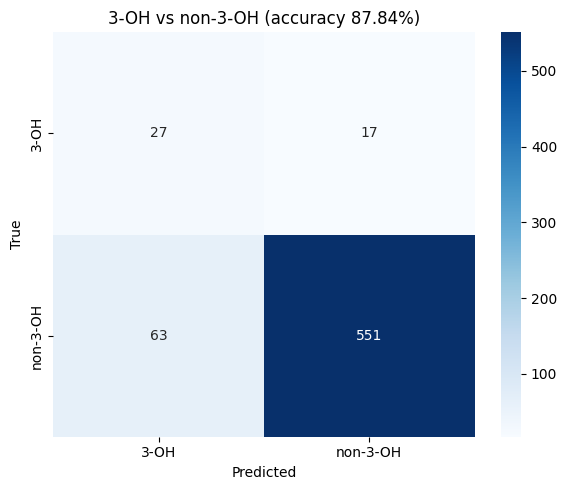

,role,n,called_3oh,fraction_called_3oh
catalogue_class,,,,
3-OH,3-OH,44,27,0.614
3-P,non-3-OH,9,5,0.556
3-Cl,non-3-OH,37,17,0.459
3-Car,non-3-OH,81,36,0.444
3-KNa,non-3-OH,33,4,0.121
3-K,non-3-OH,19,1,0.053
1,non-3-OH,92,0,0.000
2,non-3-OH,89,0,0.000
4,non-3-OH,92,0,0.000


Saved metrics, confusion matrix, per-class table and misclassified spectra to /workspaces/cda-dust-analyzer/Notebooks/3oh_classification/study_results_3oh


In [24]:
def evaluate(results_df, output_dir):
    answered = results_df[results_df["predicted_label"].isin(c3.BINARY_LABELS)]
    print(f"{len(answered)} of {len(results_df)} test spectra have a usable prediction.")
    scored = answered[answered["role"].isin(c3.BINARY_LABELS)]
    if scored.empty:
        print("Nothing to score.")
        return None

    labels = c3.BINARY_LABELS
    y_true, y_pred = scored["role"], scored["predicted_label"]
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    tp, fn, fp, tn = cm.ravel()
    metrics = {
        "model": MODEL_ID,
        "n_test": int(len(results_df)),
        "n_answered": int(len(answered)),
        "n_scored": int(len(scored)),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision_3oh": float(precision_score(y_true, y_pred, pos_label=c3.LABEL_3OH, zero_division=0)),
        "recall_3oh": float(recall_score(y_true, y_pred, pos_label=c3.LABEL_3OH, zero_division=0)),
        "f1_3oh": float(f1_score(y_true, y_pred, pos_label=c3.LABEL_3OH, zero_division=0)),
        "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn),
        "label_role": LABEL_ROLE,
    }
    print(f"Accuracy: {metrics['accuracy']:.2%}")
    print(f"3-OH  TP: {tp}, FP: {fp}, FN: {fn}, TN: {tn}")
    print(f"3-OH  Precision: {metrics['precision_3oh']:.2%} | Recall: {metrics['recall_3oh']:.2%} | F1: {metrics['f1_3oh']:.2%}")

    cm_df = pd.DataFrame(cm, index=[f"true {l}" for l in labels], columns=[f"pred {l}" for l in labels])
    cm_df.to_csv(os.path.join(output_dir, "confusion_matrix_3oh.csv"))
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
    plt.title(f"3-OH vs non-3-OH (accuracy {metrics['accuracy']:.2%})")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, "confusion_matrix_3oh.png"))
    plt.show()

    per_class = (answered.groupby("catalogue_class")
                 .agg(role=("role", "first"), n=("sclk", "size"),
                      called_3oh=("predicted_label", lambda s: int((s == c3.LABEL_3OH).sum())))
                 .assign(fraction_called_3oh=lambda d: (d["called_3oh"] / d["n"]).round(3))
                 .sort_values("fraction_called_3oh", ascending=False))
    per_class.to_csv(os.path.join(output_dir, "per_class_3oh.csv"))
    display(per_class)

    scored[scored["role"] != scored["predicted_label"]].to_csv(os.path.join(output_dir, "misclassified_3oh.csv"), index=False)
    with open(os.path.join(output_dir, "metrics_3oh.json"), "w") as f:
        json.dump(metrics, f, indent=4)
    print(f"Saved metrics, confusion matrix, per-class table and misclassified spectra to {output_dir}")
    return metrics


metrics = evaluate(results_df, OUTPUT_DIR)

## Step 11: Recheck the Metrics from the Saved CSV

658 of 716 test spectra have a usable prediction.
Accuracy: 87.84%
3-OH  TP: 27, FP: 63, FN: 17, TN: 551
3-OH  Precision: 30.00% | Recall: 61.36% | F1: 40.30%


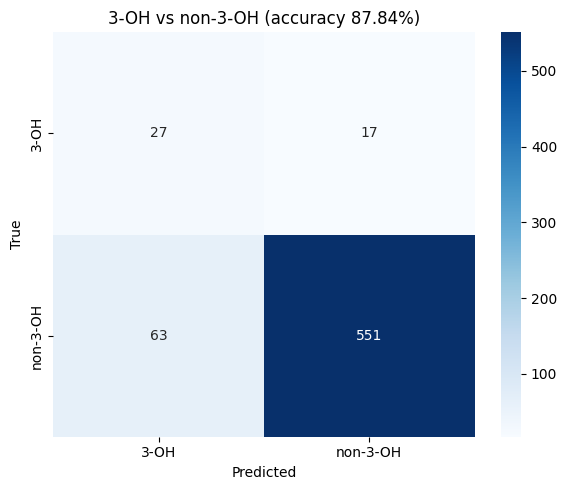

,role,n,called_3oh,fraction_called_3oh
catalogue_class,,,,
3-OH,3-OH,44,27,0.614
3-P,non-3-OH,9,5,0.556
3-Cl,non-3-OH,37,17,0.459
3-Car,non-3-OH,81,36,0.444
3-KNa,non-3-OH,33,4,0.121
3-K,non-3-OH,19,1,0.053
1,non-3-OH,92,0,0.000
2,non-3-OH,89,0,0.000
4,non-3-OH,92,0,0.000


Saved metrics, confusion matrix, per-class table and misclassified spectra to /workspaces/cda-dust-analyzer/Notebooks/3oh_classification/study_results_3oh


In [25]:
csv_path = os.path.join(OUTPUT_DIR, "results_3oh_study.csv")
if os.path.exists(csv_path):
    saved_results = pd.read_csv(csv_path, dtype={"catalogue_class": str})
    saved_results["predicted_label"] = saved_results["predicted_label"].map(c3.normalise_label)
    evaluate(saved_results, OUTPUT_DIR)
else:
    print(f"File not found: {csv_path}")